Tehdään ensin ohjelma, joka laskee DCT kantakuvat 3x3,4x4,6x6,7x7,8x8 kokoisille kuville

In [15]:
import numpy as np

def dct_matrix(N):
    """DCT-II-matriisi: A[k, n] = cos(pi*(2n+1)*k / (2N))"""
    n = np.arange(N)
    k = n.reshape(-1, 1)
    A = np.cos(np.pi * (2 * n + 1) * k / (2 * N))
    # normalisointi, jotta A on ortonormaali
    A[0, :] *= 1 / np.sqrt(2)
    A *= np.sqrt(2 / N)
    return A

for N in [3, 4, 6, 7, 8]:
    A = dct_matrix(N)
    # Kantakuvat
    basis = []
    for u in range(N):
        for v in range(N):
            B = np.outer(A[u, :], A[v, :])
            basis.append(B)
    print(f"{N}x{N}: {N*N} kantakuvaa, koko {N}x{N}")

3x3: 9 kantakuvaa, koko 3x3
4x4: 16 kantakuvaa, koko 4x4
6x6: 36 kantakuvaa, koko 6x6
7x7: 49 kantakuvaa, koko 7x7
8x8: 64 kantakuvaa, koko 8x8


Lasketaan sitten kantakuvat dct:lle kuvalle jossa on pystysuunnassa yhtä monta pikseliä kuin etunimessäni on kirjaimia.. ja vaakasuunnassa yhtä monta pikseliä kuin sukunimessäni on kirjaimia

In [16]:
import numpy as np
import matplotlib.pyplot as plt


ETUNIMI = "Janika"      
SUKUNIMI = "Ahonen"  

H = len(ETUNIMI)   # pystysuunnan pikselit
W = len(SUKUNIMI)  # vaakasuunnan pikselit
print(f"Etunimi '{ETUNIMI}': {H} kirjainta, sukunimi '{SUKUNIMI}': {W} kirjainta")
print(f"Kuva on {H}x{W} = {H*W} pikseliä, eli DCT-kantakuvia/kertoimia tulee {H*W}")
print(f"Vertailu: pikselimäärä on nimipituuksien TULO ({H}*{W}), ei summa ({H}+{W})")

Etunimi 'Janika': 6 kirjainta, sukunimi 'Ahonen': 6 kirjainta
Kuva on 6x6 = 36 pikseliä, eli DCT-kantakuvia/kertoimia tulee 36
Vertailu: pikselimäärä on nimipituuksien TULO (6*6), ei summa (6+6)


Ortonormaali DCT-II-matriisi

In [17]:
def dct_matrix(N):
   
    n = np.arange(N)
    k = n.reshape(-1, 1)
    A = np.cos(np.pi * (2 * n + 1) * k / (2 * N))
    A[0, :] *= 1 / np.sqrt(2)
    A *= np.sqrt(2 / N)
    return A


Kantakuvat: jokainen on pysty- ja vaakasuuntaisen kosinifunktion tulo (ulkotulo) ja Kaikki kantakuvat ruudukkoon

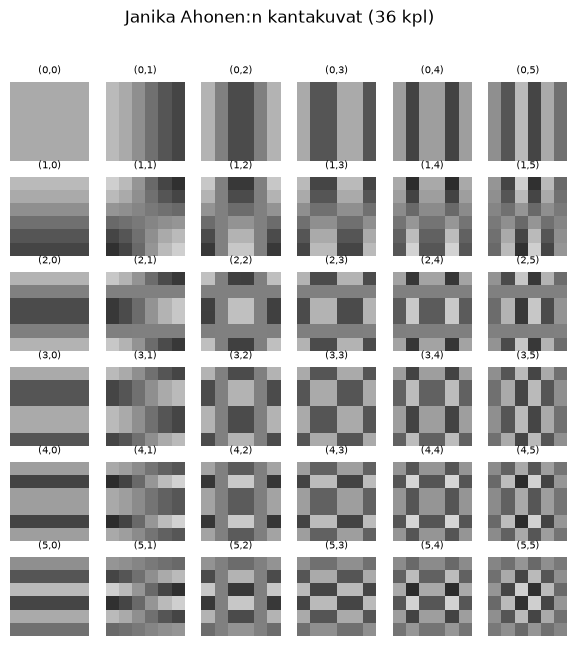

In [18]:

Ah, Aw = dct_matrix(H), dct_matrix(W)
basis = {}
for u in range(H):
    for v in range(W):
        basis[(u, v)] = np.outer(Ah[u, :], Aw[v, :])  # H x W -kuva


fig, axes = plt.subplots(H, W, figsize=(W * 1.2, H * 1.2))
for i in range(H):
    for j in range(W):
        ax = axes[i, j]
        ax.imshow(basis[(i, j)], cmap="gray", vmin=-0.5, vmax=0.5)
        ax.set_title(f"({i},{j})", fontsize=7)
        ax.axis("off")
fig.suptitle(f"{ETUNIMI} {SUKUNIMI}:n kantakuvat ({H*W} kpl)")
fig.savefig(f"{ETUNIMI} {SUKUNIMI} kantakuvat.png", dpi=150, bbox_inches="tight")


In [19]:

rng = np.random.default_rng(42)
test_image = rng.random((H, W))  

coeffs = {}
for (u, v), B in basis.items():
    coeffs[(u, v)] = np.sum(test_image * B) 

reconstruction = np.zeros((H, W))
for (u, v), c in coeffs.items():
    reconstruction += c * basis[(u, v)]

print(f"Kertoimia käytettiin: {len(coeffs)} (yhtä monta kuin pikselejä: {H*W})")
print(f"Suurin palautusvirhe: {np.max(np.abs(test_image - reconstruction)):.2e}")

Kertoimia käytettiin: 36 (yhtä monta kuin pikselejä: 36)
Suurin palautusvirhe: 1.67e-15


valitsin 2,4 kuvan koska siinä on mielestäni silmät ja nenä. Joten se näyttää minulta.

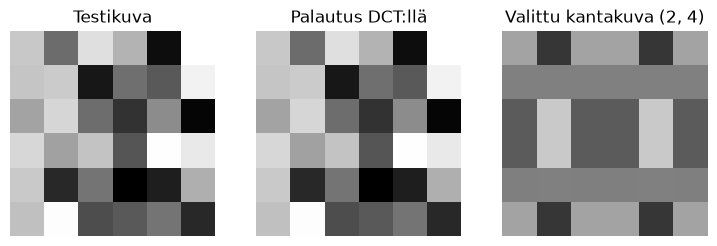

In [21]:

valinta = (2, 4)  
fig2, axes2 = plt.subplots(1, 3, figsize=(9, 3))
axes2[0].imshow(test_image, cmap="gray");      axes2[0].set_title("Testikuva")
axes2[1].imshow(reconstruction, cmap="gray");  axes2[1].set_title("Palautus DCT:llä")
axes2[2].imshow(basis[valinta], cmap="gray", vmin=-0.5, vmax=0.5)
axes2[2].set_title(f"Valittu kantakuva {valinta}")
for ax in axes2: ax.axis("off")
fig2.savefig(f"{ETUNIMI} {SUKUNIMI} lopputulos.png", dpi=150, bbox_inches="tight")
plt.show()

